### Import Libraries

`Pandas` is used for analyzing and manipulating data. `NumPy`is used for numerical calculations. `Matplotlib` is a data visualization library. `Seaborn` is used for creating statistical data visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load the Dataset

I use `pd.read_csv` to load the dataset exported from SQL.

In [2]:
data = pd.read_csv('Dataset.csv')
data.head(10)

,location_id,country,city,state,postal_code,region,product_id,category,sub_category,sale_id,sales,quantity,discount,profit,segment_id,segment,shipping_id,ship_mode
0,2,United States,Los Angeles,California,90036,West,11,Office Supplies,Paper,9,32.400,5,0.0,15.552,3,Home Office,1,Second Class
1,15,United States,Houston,Texas,77095,Central,5,Office Supplies,Storage,111,158.368,7,0.2,13.857,3,Home Office,1,Second Class
2,15,United States,Houston,Texas,77095,Central,11,Office Supplies,Paper,112,29.472,3,0.2,9.947,3,Home Office,1,Second Class
3,17,United States,Houston,Texas,77041,Central,2,Furniture,Chairs,129,600.558,3,0.3,-8.579,3,Home Office,1,Second Class
4,24,United States,New York City,New York,10024,East,2,Furniture,Chairs,156,1242.900,5,0.1,262.390,3,Home Office,1,Second Class
5,24,United States,New York City,New York,10024,East,9,Office Supplies,Binders,157,68.472,3,0.2,23.109,3,Home Office,1,Second Class
6,26,United States,Los Angeles,California,90004,West,6,Furniture,Furnishings,201,238.560,3,0.0,26.242,3,Home Office,1,Second Class
7,26,United States,Los Angeles,California,90004,West,2,Furniture,Chairs,202,81.424,2,0.2,-9.160,3,Home Office,1,Second Class
8,30,United States,New York City,New York,10009,East,6,Furniture,Furnishings,267,96.530,7,0.0,40.543,3,Home Office,1,Second Class
9,37,United States,Chicago,Illinois,60623,Central,11,Office Supplies,Paper,308,313.488,7,0.2,113.639,3,Home Office,1,Second Class


### Data overview

The dataset has been loaded as a DataFrame with 9977 rows and 18 columns. The data types are integer, float and object. There are no missing values and no duplicated rows. Then I checked basic statistical properties.

In [3]:
data.shape

(9977, 18)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9977 entries, 0 to 9976
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   location_id   9977 non-null   int64  
 1   country       9977 non-null   object 
 2   city          9977 non-null   object 
 3   state         9977 non-null   object 
 4   postal_code   9977 non-null   int64  
 5   region        9977 non-null   object 
 6   product_id    9977 non-null   int64  
 7   category      9977 non-null   object 
 8   sub_category  9977 non-null   object 
 9   sale_id       9977 non-null   int64  
 10  sales         9977 non-null   float64
 11  quantity      9977 non-null   int64  
 12  discount      9977 non-null   float64
 13  profit        9977 non-null   float64
 14  segment_id    9977 non-null   int64  
 15  segment       9977 non-null   object 
 16  shipping_id   9977 non-null   int64  
 17  ship_mode     9977 non-null   object 
dtypes: float64(3), int64(7), obj

In [5]:
data.duplicated().sum()

0

In [6]:
data.isnull().sum()

location_id     0
country         0
city            0
state           0
postal_code     0
region          0
product_id      0
category        0
sub_category    0
sale_id         0
sales           0
quantity        0
discount        0
profit          0
segment_id      0
segment         0
shipping_id     0
ship_mode       0
dtype: int64

In [7]:
data.describe()

,location_id,postal_code,product_id,sale_id,sales,quantity,discount,profit,segment_id,shipping_id
count,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000,9977.000000
mean,159.522602,55154.964117,8.144633,4989.000000,230.148902,3.790719,0.156278,28.690144,1.658815,2.067956
std,150.666719,32058.266816,3.523781,2880.256152,623.721409,2.226657,0.206455,234.457850,0.762533,0.749360
min,1.000000,1040.000000,1.000000,1.000000,0.444000,1.000000,0.000000,-6599.978000,1.000000,1.000000
25%,39.000000,23223.000000,6.000000,2495.000000,17.300000,2.000000,0.000000,1.726000,1.000000,2.000000
50%,106.000000,55901.000000,8.000000,4989.000000,54.816000,3.000000,0.200000,8.671000,1.000000,2.000000
75%,239.000000,90008.000000,11.000000,7483.000000,209.970000,5.000000,0.200000,29.372000,2.000000,2.000000
max,632.000000,99301.000000,17.000000,9977.000000,22638.480000,14.000000,0.800000,8399.976000,3.000000,4.000000


### Correlation Heatmap

I create a heatmap to examine the relationships between the five numerical variables in the dataset.
A correlation coefficient ranges from -1 (strong negative relationship) to +1 (strong positive relationship). A value around 0 indicates little or no linear relationship.
The heatmap will help identify potential relationships and patterns between the numerical variables.

In [33]:
data = pd.read_csv("Dataset.csv")

In [24]:
data["profit_margin"] = (data["profit"] / data["sales"]) * 100

In [29]:
data_subset = data[["sales", "profit", "profit_margin", "quantity", "discount"]]

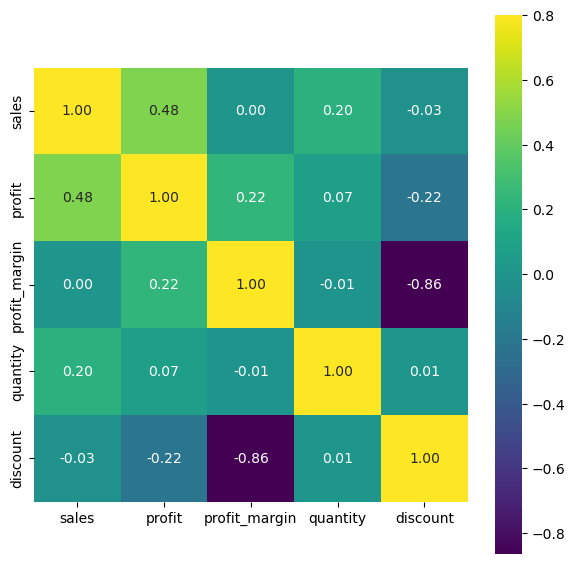

In [31]:
corrmatrix = data_subset.corr()
plt.subplots(figsize = (7,7))
sns.heatmap(corrmatrix,vmax = .8, square = True, annot = True, fmt = ".2f", cmap = "viridis")
plt.show()